# Peramalan Konsumsi Daya Listrik dengan Transfer Learning
Model: **Chronos-Bolt** (pre-trained foundation model time series) → zero-shot & fine-tuning, dibandingkan dengan baseline.

> Jalankan di Google Colab (Runtime → GPU T4 direkomendasikan).

In [31]:
!pip install -q autogluon.timeseries openpyxl

## 1. Muat & bersihkan data

In [32]:
import pandas as pd, numpy as np, matplotlib.pyplot as plt
PATH = '/datapbl.xlsx'  # Colab: upload file ke sidebar Files. Jika dari root repo: 'data/datapbl.xlsx'
df = pd.read_excel(PATH)
df['PERIOD'] = pd.to_datetime(df['PERIOD'].astype(str).str[:19])
s = df.set_index('PERIOD')['MAIN_POWER_HOURLY']
print(s.describe())

count    3.781000e+03
mean     7.139920e+02
std      3.367809e+04
min     -1.255168e+06
25%      1.382000e+01
50%      2.444000e+01
75%      6.338000e+01
max      1.458803e+06
Name: MAIN_POWER_HOURLY, dtype: float64


Jam kosong sebelum interpolasi: 0
Jumlah segmen kontinu dipakai: 1 | panjang (jam): [3781]


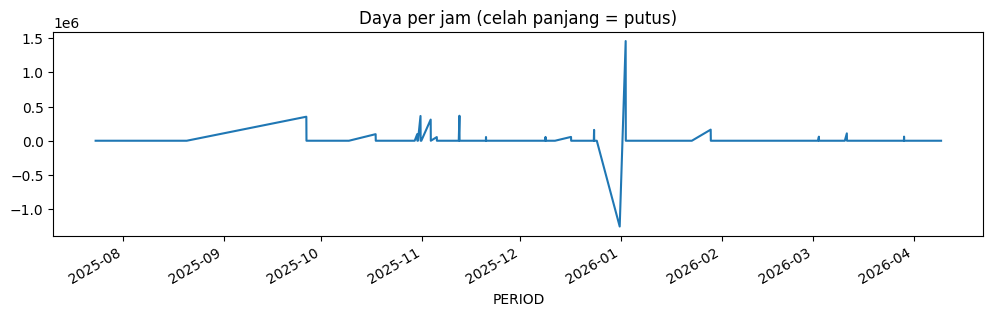

In [33]:
print('Jam kosong sebelum interpolasi:', s.isna().sum())
s = s.interpolate(limit=24)   # isi celah pendek (<=24 jam); celah panjang tetap NaN
# Celah panjang (hingga 882 jam) TIDAK diisi paksa -> data dipecah jadi segmen kontinu
valid = s.notna()
seg_id = (valid != valid.shift()).cumsum()
segments = {i: g for i, g in s[valid].groupby(seg_id[valid]) if len(g) >= 336}  # min 2 minggu
print('Jumlah segmen kontinu dipakai:', len(segments), '| panjang (jam):', [len(g) for g in segments.values()])
s.plot(figsize=(12,3), title='Daya per jam (celah panjang = putus)'); plt.show()

## 2. Format AutoGluon & split kronologis
Tiap segmen kontinu dijadikan satu deret. Test = 7 hari terakhir setiap segmen; horizon prediksi 24 jam.

In [34]:
from autogluon.timeseries import TimeSeriesDataFrame, TimeSeriesPredictor

# Tiap segmen kontinu = 1 deret (item_id) -> TimeSeriesDataFrame
d = pd.concat([g.rename('target').reset_index().rename(columns={'PERIOD':'timestamp'}).assign(item_id=f'seg{i}')
               for i, g in segments.items()])
ts = TimeSeriesDataFrame.from_data_frame(d, id_column='item_id', timestamp_column='timestamp')
H = 24
train_val = ts.slice_by_timestep(None, -7*24)   # tiap segmen: 7 hari terakhir ditahan sebagai test
print(ts.num_items, len(ts), len(train_val))

1 3781 3613


## 3. Model: baseline vs transfer learning
- `SeasonalNaive` → baseline (tanpa belajar)
- `Chronos_ZeroShot` → transfer learning tanpa pelatihan
- `Chronos_FineTuned` → transfer learning + fine-tune di data Anda
- `DeepAR` → neural net dilatih dari nol (pembanding tanpa transfer learning)

In [35]:
predictor = TimeSeriesPredictor(prediction_length=H, target='target', freq='h',
                                eval_metric='MAE', path='models/ag').fit(
    train_val,
    hyperparameters={
        'SeasonalNaive': {'seasonal_period': 24},
        'Chronos': [
            {'model_path': 'bolt_small', 'ag_args': {'name': 'Chronos_ZeroShot'}},
            {'model_path': 'bolt_small', 'fine_tune': True, 'fine_tune_steps': 1000,
             'ag_args': {'name': 'Chronos_FineTuned'}},
        ],
        'DeepAR': {'max_epochs': 20},
    },
    enable_ensemble=False, time_limit=1800)

Beginning AutoGluon training... Time limit = 1800s
AutoGluon will save models to '/content/models/ag'
=================== System Info ===================
AutoGluon Version:  1.6.3
Python Version:     3.13.15
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP Thu Apr 30 18:17:14 UTC 2026
CPU Count:          2
Pytorch Version:    2.11.0+cu130
CUDA Version:       13.0
GPU Memory:         GPU 0: 14.55/14.56 GB
Total GPU Memory:   Free: 14.55 GB, Allocated: 0.01 GB, Total: 14.56 GB
GPU Count:          1
Memory Avail:       9.21 GB / 12.67 GB (72.7%)
Disk Space Avail:   68.98 GB / 112.64 GB (61.2%)

Fitting with arguments:
{'enable_ensemble': False,
 'eval_metric': MAE,
 'freq': 'h',
 'hyperparameters': {'Chronos': [{'ag_args': {'name': 'Chronos_ZeroShot'},
                                  'model_path': 'bolt_small'},
                                 {'ag_args': {'name': 'Chronos_FineTuned'},
                                  'fine_tune': True,
                 

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

	-23.1708      = Validation score (-MAE)
	0.02    s     = Training runtime
	1.58    s     = Validation (prediction) runtime
Training timeseries model Chronos_FineTuned[bolt_small]. Training for up to 899.2s of the 1798.3s of remaining time.
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchronos-bolt-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%22d8f9b65552d4d211e28d332ad5666484092bbf77%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchrono

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

	Saving fine-tuned model to /content/models/ag/models/Chronos_FineTuned[bolt_small]/W0/fine-tuned-ckpt


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

	-34.4198      = Validation score (-MAE)
	251.51  s     = Training runtime
	0.03    s     = Validation (prediction) runtime
Training timeseries model DeepAR. Training for up to 1546.8s of the 1546.8s of remaining time.
	-14.7280      = Validation score (-MAE)
	20.77   s     = Training runtime
	0.14    s     = Validation (prediction) runtime
Training complete. Models trained: ['SeasonalNaive', 'Chronos_ZeroShot[bolt_small]', 'Chronos_FineTuned[bolt_small]', 'DeepAR']
Total runtime: 274.11 s
Best model: SeasonalNaive
Best model score: -6.4571


## 4. Evaluasi di data test (7 hari terakhir tiap segmen)

In [36]:
lb = predictor.leaderboard(ts, extra_metrics=['RMSE','MAPE'])
lb['MAE'] = -lb['score_test']; lb['RMSE'] = -lb['RMSE']; lb['MAPE'] = -lb['MAPE']
res = lb[['model','MAE','RMSE','MAPE']].sort_values('MAE')
res.to_csv('results_metrics.csv', index=False); res

data with frequency 'IRREG' has been resampled to frequency 'h'.
Additional data provided, testing on additional data. Resulting leaderboard will be sorted according to test score (`score_test`).
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchronos-bolt-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%22d8f9b65552d4d211e28d332ad5666484092bbf77%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchronos-bolt-small%2Fresolve%2Fmain%2Fconfig.json=&

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

,model,MAE,RMSE,MAPE
0,SeasonalNaive,8.342083,15.503547,0.230068
1,DeepAR,12.427724,17.724820,0.394041
2,Chronos_ZeroShot[bolt_small],22.877588,25.183767,1.148890
3,Chronos_FineTuned[bolt_small],28.646848,35.172721,0.678507


## 5. Grafik prediksi vs aktual (24 jam terakhir)

data with frequency 'IRREG' has been resampled to frequency 'h'.
data with frequency 'IRREG' has been resampled to frequency 'h'.
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchronos-bolt-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%22d8f9b65552d4d211e28d332ad5666484092bbf77%22 "HTTP/1.1 200 OK"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/autogluon/chronos-bolt-small/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
INFO:httpx:HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/autogluon/chronos-bolt-small/2e1597a7bae01316fcea6a9da90451890b529096/config.json?%2Fautogluon%2Fchronos-bolt-small%2Fresolve%2Fmain%2Fconfig.json=&etag=%22d8f9b65552d4d211e28d332ad5666484092bbf77%22 "HTTP/1.1 200 

Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

data with frequency 'IRREG' has been resampled to frequency 'h'.


Loading weights:   0%|          | 0/143 [00:00<?, ?it/s]

data with frequency 'IRREG' has been resampled to frequency 'h'.


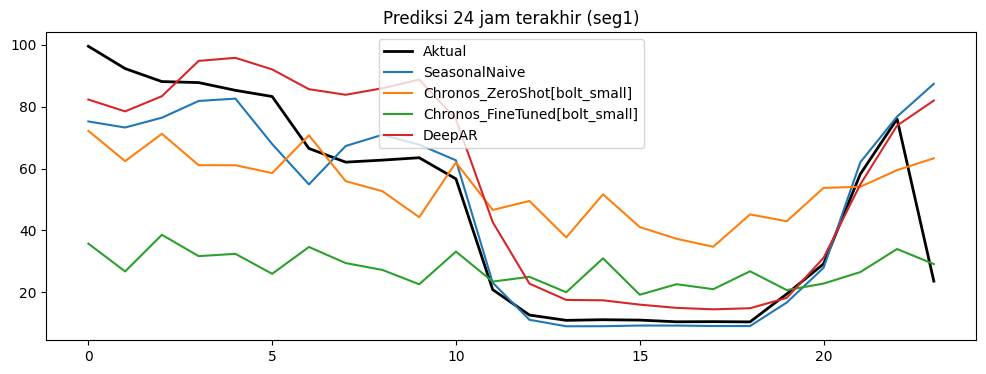

In [37]:
item = ts.item_ids[0]   # contoh: segmen pertama
hist = ts.slice_by_timestep(None, -H)
actual = ts.slice_by_timestep(-H, None).loc[item]['target'].values
fig, ax = plt.subplots(figsize=(12,4))
ax.plot(actual, 'k', lw=2, label='Aktual')
for m in predictor.model_names():
    p = predictor.predict(hist, model=m).loc[item]['mean'].values
    ax.plot(p, label=m)
ax.set_title(f'Prediksi 24 jam terakhir ({item})'); ax.legend()
plt.savefig('results_forecast.png', dpi=150); plt.show()

## 6. Kesimpulan
Penelitian ini membangun model peramalan konsumsi daya listrik per jam menggunakan transfer learning dengan model Chronos-Bolt, lalu membandingkannya dengan baseline SeasonalNaive dan model DeepAR yang dilatih dari nol. Berdasarkan hasil evaluasi pada data uji (7 hari terakhir tiap segmen), model terbaik adalah ___ dengan nilai MAE sebesar ___ dan RMSE sebesar ___.

Model Chronos hasil fine-tuning menghasilkan MAE ___, yang (lebih baik / lebih buruk) ___% dibandingkan baseline SeasonalNaive dengan MAE ___. Fine-tuning juga (memperbaiki / tidak banyak mengubah) hasil Chronos zero-shot, dari MAE ___ menjadi ___. Jika dibandingkan dengan DeepAR yang dilatih dari nol (MAE ___), Chronos (lebih akurat / kurang akurat), sehingga transfer learning (terbukti / belum terbukti) bermanfaat pada data ini.

Penelitian ini memiliki beberapa keterbatasan. Data hanya mencakup sekitar lima bulan dan terpecah menjadi lima segmen karena adanya celah pengukuran yang panjang. Sebanyak 17 nilai outlier sensor dibuang, dan celah yang pendek diisi dengan interpolasi. Selain itu, waktu pelatihan dibatasi karena menggunakan Google Colab versi gratis, dan evaluasi hanya dilakukan pada periode uji yang singkat. Untuk penelitian selanjutnya, disarankan menambah jumlah data, menambahkan fitur kalender seperti hari libur, dan mencoba model Chronos yang lebih besar.
